device: mps
k=1: Var(clean target) = 1.0079, Var(y) = 1.1064
k=2: Var(clean target) = 1.0163, Var(y) = 1.1186
k=3: Var(clean target) = 1.0219, Var(y) = 1.1263
h=  16: d_param =   513, LLC upper bound d_param/2 = 256.5
h=  32: d_param =  1025, LLC upper bound d_param/2 = 512.5
h=  64: d_param =  2049, LLC upper bound d_param/2 = 1024.5
h= 128: d_param =  4097, LLC upper bound d_param/2 = 2048.5
k=1, h=  16: final test MSE = 0.1022, min-gap epoch = 1
k=1, h=  32: final test MSE = 0.1037, min-gap epoch = 1
k=1, h=  64: final test MSE = 0.1064, min-gap epoch = 1
k=1, h= 128: final test MSE = 0.1131, min-gap epoch = 1
k=2, h=  16: final test MSE = 0.1039, min-gap epoch = 1
k=2, h=  32: final test MSE = 0.1043, min-gap epoch = 1
k=2, h=  64: final test MSE = 0.1075, min-gap epoch = 1
k=2, h= 128: final test MSE = 0.1131, min-gap epoch = 1
k=3, h=  16: final test MSE = 0.1091, min-gap epoch = 1
k=3, h=  32: final test MSE = 0.1083, min-gap epoch = 1
k=3, h=  64: final test MSE = 0.1109, min-g

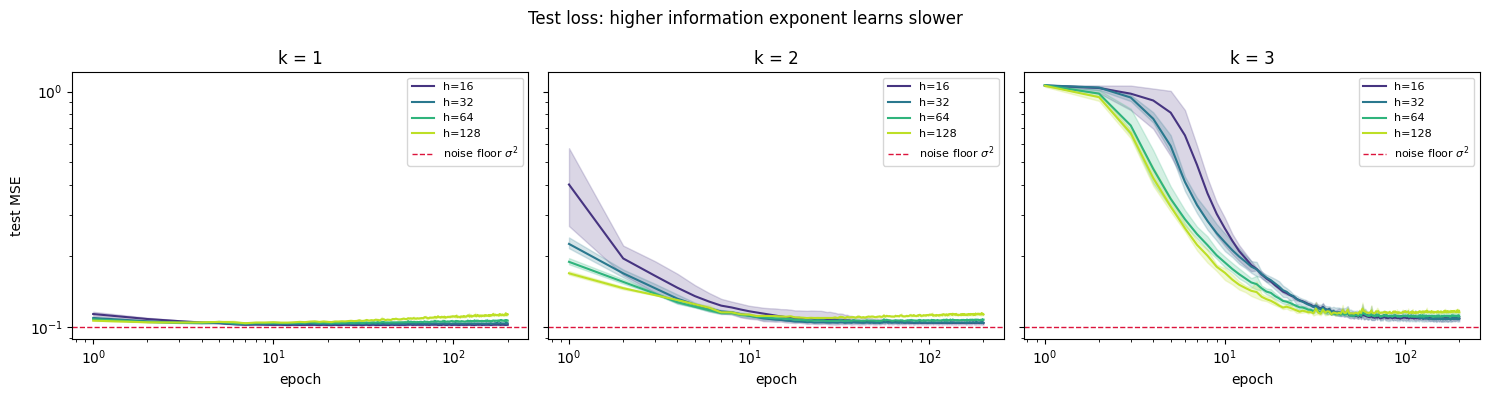

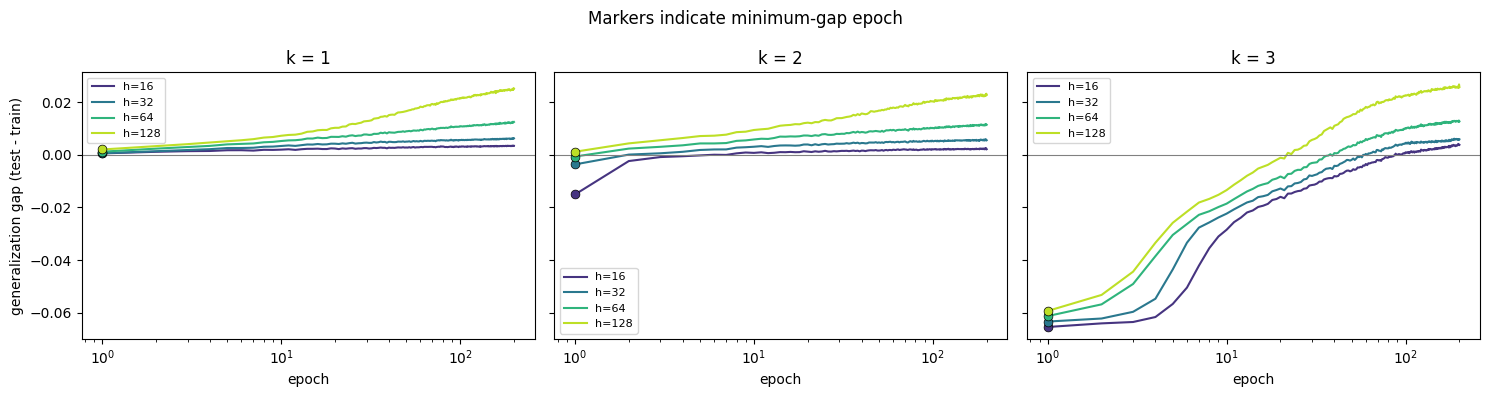

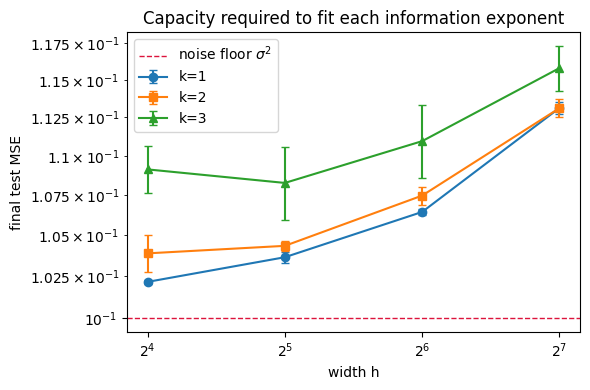

In [3]:
# %% [markdown]
# # 段階1: Hermite 回帰タスクの学習曲線
#
# タスク: x ~ N(0, I_d), y = He_k(<w*, x>)/sqrt(k!) + noise
# k = 1, 2, 3 で information exponent を変え、学習の難しさと汎化ギャップを見る。
# 目的: k=3 が学習できる最小の幅 h を決めること。

# %%
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from math import factorial
from itertools import product

# %%
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

device = get_device()
print(f"device: {device}")

# %% [markdown]
# ## 設定

# %%
CFG = dict(
    d=30,                 # 入力次元
    n_train=50_000,       # 訓練サンプル数（全条件で固定：nβ を揃えるため）
    n_test=20_000,
    sigma=np.sqrt(0.1),   # 観測ノイズの標準偏差
    batch_size=128,
    lr=1e-3,
    weight_decay=0.0,     # LLC の解釈を単純にするため一旦ゼロ
    epochs=200,
    eval_every=1,
)

K_LIST = [1, 2, 3]
H_LIST = [16, 32, 64, 128]
DATA_SEED = 0
INIT_SEEDS = [0, 1, 2]

# %% [markdown]
# ## データ生成

# %%
def hermite_prob(j, z):
    """He_j(z): N(0,1) に関して直交する Hermite 多項式。
    He_0=1, He_1=z, He_{n+1}(z) = z·He_n(z) - n·He_{n-1}(z)
    """
    if j == 0:
        return torch.ones_like(z)
    Hm1, H = torch.ones_like(z), z.clone()
    for n in range(1, j):
        Hm1, H = H, z * H - n * Hm1
    return H


def make_dataset(k, cfg, seed):
    """He_k ターゲットの回帰データを生成。
    ターゲットは sqrt(k!) で正規化し、全 k で Var = 1 に揃える。
    """
    g = torch.Generator().manual_seed(seed)
    d = cfg["d"]

    # 教師方向（単位ベクトル）。全 k で同じ方向を使う
    w_star = torch.randn(d, generator=g)
    w_star = w_star / w_star.norm()

    def sample(n, gen):
        X = torch.randn(n, d, generator=gen)
        z = X @ w_star
        y_clean = hermite_prob(k, z) / np.sqrt(factorial(k))
        y = y_clean + cfg["sigma"] * torch.randn(n, generator=gen)
        return X, y, y_clean

    g_tr = torch.Generator().manual_seed(seed + 100)
    g_te = torch.Generator().manual_seed(seed + 200)
    Xtr, ytr, _ = sample(cfg["n_train"], g_tr)
    Xte, yte, yte_clean = sample(cfg["n_test"], g_te)
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, yte_clean=yte_clean,
                w_star=w_star)


# サニティチェック: ターゲットの分散が k によらず 1 か
for k in K_LIST:
    ds = make_dataset(k, CFG, DATA_SEED)
    z = ds["Xtr"] @ ds["w_star"]
    yc = hermite_prob(k, z) / np.sqrt(factorial(k))
    print(f"k={k}: Var(clean target) = {yc.var().item():.4f}, "
          f"Var(y) = {ds['ytr'].var().item():.4f}")

# %% [markdown]
# ## モデル

# %%
class TwoLayerReLU(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.fc1 = nn.Linear(d, h)
        self.fc2 = nn.Linear(h, 1)

    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x))).squeeze(-1)


def n_params(d, h):
    return d * h + h + h + 1

for h in H_LIST:
    print(f"h={h:4d}: d_param = {n_params(CFG['d'], h):5d}, "
          f"LLC upper bound d_param/2 = {n_params(CFG['d'], h)/2:.1f}")

# %% [markdown]
# ## 学習ループ

# %%
@torch.no_grad()
def eval_mse(model, X, y, bs=4096):
    model.eval()
    tot = 0.0
    for i in range(0, len(X), bs):
        pred = model(X[i:i+bs])
        tot += ((pred - y[i:i+bs]) ** 2).sum().item()
    return tot / len(X)


def train_one(k, h, cfg, data_seed, init_seed):
    ds = make_dataset(k, cfg, data_seed)
    Xtr, ytr = ds["Xtr"].to(device), ds["ytr"].to(device)
    Xte, yte = ds["Xte"].to(device), ds["yte"].to(device)

    torch.manual_seed(init_seed)
    model = TwoLayerReLU(cfg["d"], h).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"],
                           weight_decay=cfg["weight_decay"])

    n = len(Xtr)
    hist = {key: [] for key in ["epoch", "train", "test", "gap"]}

    for ep in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, cfg["batch_size"]):
            idx = perm[i:i+cfg["batch_size"]]
            loss = ((model(Xtr[idx]) - ytr[idx]) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

        if (ep + 1) % cfg["eval_every"] == 0 or ep == 0:
            tr = eval_mse(model, Xtr, ytr)
            te = eval_mse(model, Xte, yte)
            hist["epoch"].append(ep + 1)
            hist["train"].append(tr)
            hist["test"].append(te)
            hist["gap"].append(te - tr)

    return model, {key: np.array(v) for key, v in hist.items()}

# %% [markdown]
# ## 全条件を走らせる

# %%
results = {}
for k, h in product(K_LIST, H_LIST):
    runs = []
    for s in INIT_SEEDS:
        _, hist = train_one(k, h, CFG, DATA_SEED, s)
        runs.append(hist)
    results[(k, h)] = runs
    final_te = np.mean([r["test"][-1] for r in runs])
    min_gap_ep = np.mean([r["epoch"][np.argmin(r["gap"])] for r in runs])
    print(f"k={k}, h={h:4d}: final test MSE = {final_te:.4f}, "
          f"min-gap epoch = {min_gap_ep:.0f}")

# %% [markdown]
# ## 学習曲線

# %%
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
cmap = plt.cm.viridis(np.linspace(0.15, 0.9, len(H_LIST)))

for ax, k in zip(axes, K_LIST):
    for c, h in zip(cmap, H_LIST):
        runs = results[(k, h)]
        te = np.stack([r["test"] for r in runs])
        ep = runs[0]["epoch"]
        ax.plot(ep, te.mean(0), color=c, label=f"h={h}")
        ax.fill_between(ep, te.min(0), te.max(0), color=c, alpha=0.2)
    ax.axhline(CFG["sigma"] ** 2, color="crimson", ls="--", lw=1,
               label=r"noise floor $\sigma^2$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"k = {k}")
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("test MSE")
fig.suptitle("Test loss: higher information exponent learns slower")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 汎化ギャップ

# %%
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, K_LIST):
    for c, h in zip(cmap, H_LIST):
        runs = results[(k, h)]
        gap = np.stack([r["gap"] for r in runs])
        ep = runs[0]["epoch"]
        ax.plot(ep, gap.mean(0), color=c, label=f"h={h}")
        # 平均ギャップの最小点
        j = np.argmin(gap.mean(0))
        ax.scatter([ep[j]], [gap.mean(0)[j]], color=c, s=40, zorder=5,
                   edgecolor="k", linewidth=0.5)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xscale("log")
    ax.set_title(f"k = {k}")
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("generalization gap (test - train)")
fig.suptitle("Markers indicate minimum-gap epoch")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 幅 h の選択
# 最終テスト損失を h の関数として見る。k=3 が noise floor に十分近づく
# 最小の h を採用する。

# %%
fig, ax = plt.subplots(figsize=(6, 4))
for k, mk in zip(K_LIST, ["o", "s", "^"]):
    finals = [np.mean([r["test"][-1] for r in results[(k, h)]]) for h in H_LIST]
    errs = [np.std([r["test"][-1] for r in results[(k, h)]]) for h in H_LIST]
    ax.errorbar(H_LIST, finals, yerr=errs, marker=mk, capsize=3, label=f"k={k}")
ax.axhline(CFG["sigma"] ** 2, color="crimson", ls="--", lw=1,
           label=r"noise floor $\sigma^2$")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("width h")
ax.set_ylabel("final test MSE")
ax.set_title("Capacity required to fit each information exponent")
ax.legend()
plt.tight_layout()
plt.show()

log


```
device: mps
k=1: Var(clean target) = 1.0079, Var(y) = 1.1064
k=2: Var(clean target) = 1.0163, Var(y) = 1.1186
k=3: Var(clean target) = 1.0219, Var(y) = 1.1263
h=  16: d_param =   513, LLC upper bound d_param/2 = 256.5
h=  32: d_param =  1025, LLC upper bound d_param/2 = 512.5
h=  64: d_param =  2049, LLC upper bound d_param/2 = 1024.5
h= 128: d_param =  4097, LLC upper bound d_param/2 = 2048.5
k=1, h=  16: final test MSE = 0.1022, min-gap epoch = 1
k=1, h=  32: final test MSE = 0.1037, min-gap epoch = 1
k=1, h=  64: final test MSE = 0.1064, min-gap epoch = 1
k=1, h= 128: final test MSE = 0.1131, min-gap epoch = 1
k=2, h=  16: final test MSE = 0.1039, min-gap epoch = 1
k=2, h=  32: final test MSE = 0.1043, min-gap epoch = 1
k=2, h=  64: final test MSE = 0.1075, min-gap epoch = 1
k=2, h= 128: final test MSE = 0.1131, min-gap epoch = 1
k=3, h=  16: final test MSE = 0.1091, min-gap epoch = 1
k=3, h=  32: final test MSE = 0.1083, min-gap epoch = 1
k=3, h=  64: final test MSE = 0.1109, min-gap epoch = 1
k=3, h= 128: final test MSE = 0.1158, min-gap epoch = 1
```